# NTK Weights for the PINN Boundary Loss

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kks32-courses/sciml/blob/main/docs/01-pinns/ntk-boundary-weights.ipynb)

The NTK matrix is formed by taking the derivatives of the neural network outputs with respect to all its trainable parameters, then computing dot products between those derivatives.

For PINNs, we do the same thing, except that we also differentiate the PDE residuals with respect to the network parameters.

Let's construct one explicitly.

## 1. Start with a neural network

Suppose we approximate a displacement field:

$$
u_\theta(x)
$$

where the neural network has $P$ parameters:

$$
\theta=[\theta_1,\theta_2,\ldots,\theta_P]^T
$$

Evaluate the network at $N$ locations, $x_1,\ldots,x_N$.
We construct the Jacobian:

$$
\mathbf J=
\begin{bmatrix}
\frac{\partial u(x_1)}{\partial\theta_1}&\cdots&\frac{\partial u(x_1)}{\partial\theta_P}\\
\frac{\partial u(x_2)}{\partial\theta_1}&\cdots&\frac{\partial u(x_2)}{\partial\theta_P}\\
\vdots&\ddots&\vdots\\
\frac{\partial u(x_N)}{\partial\theta_1}&\cdots&\frac{\partial u(x_N)}{\partial\theta_P}
\end{bmatrix}
$$

Each row describes how the network prediction at one location responds to changes in its weights.

### Forming the NTK

$$
\boxed{\mathbf K=\mathbf J\mathbf J^T}
$$

The NTK matrix is $N\times N$, regardless of how many parameters the network has.
Each entry is

$$
K_{ij}=\sum_{p=1}^{P}
\frac{\partial u(x_i)}{\partial\theta_p}
\frac{\partial u(x_j)}{\partial\theta_p}
$$

So $K_{ij}$ measures how similarly the predictions at locations $i$ and $j$ respond to parameter changes.

The figure draws the product for $N = 4$ locations and $P = 7$ parameters with random entries, and a darker cell holds a larger entry.
Row 2 of $J$ and column 3 of $J^T$, which is row 3 of $J$, give the outlined entry $K_{23}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def rounded_box(ax, x, y, w, h, r, **kw):
    """Rounded rectangle with lower-left corner (x, y), width w, height h, and corner radius r."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0,rounding_size={r}", **kw))

def draw_product(J, i=1, j=2, title=None):
    """Draw K = J J^T with each matrix at its true shape, and outline the rows of J that give K_ij."""
    N, P = J.shape
    K = J @ J.T
    x_T, x_K = P + 1.6, P + N + 3.2   # left edges of J^T and K
    fig, ax = plt.subplots(figsize=(11, 5.2), dpi=120)
    for name, M, x0, edge, cmap, shape in [("J", J, 0.0, "#3a76b9", plt.cm.Blues, r"$N\times P$"),
                                           (r"J^{\mathsf{T}}", J.T, x_T, "#3a76b9", plt.cm.Blues, r"$P\times N$"),
                                           ("K", K, x_K, "#4a9a6a", plt.cm.Greens, r"$N\times N$")]:
        rows, cols = M.shape
        top = rows / 2
        rounded_box(ax, x0 - 0.15, -top - 0.15, cols + 0.3, rows + 0.3, 0.35, facecolor=edge, alpha=0.1, edgecolor="none")
        rounded_box(ax, x0 - 0.15, -top - 0.15, cols + 0.3, rows + 0.3, 0.35, facecolor="none", edgecolor=edge, lw=2.5)
        shade = np.abs(M) / np.abs(M).max()   # darker cells hold larger entries
        for r in range(rows):
            for c in range(cols):
                rounded_box(ax, x0 + c + 0.1, top - r - 0.9, 0.8, 0.8, 0.12,
                            facecolor=cmap(0.2 + 0.5 * shade[r, c]), edgecolor="none")
        ax.text(x0 + cols / 2, top + 0.55, f"${name}$", ha="center", va="bottom", fontsize=26)
        ax.text(x0 + cols / 2, -top - 0.55, shape, ha="center", va="top", fontsize=20)
    outline = dict(facecolor="none", edgecolor="#e07b24", lw=3)
    rounded_box(ax, 0.05, N / 2 - i - 0.95, P - 0.1, 0.9, 0.2, **outline)        # row i of J
    rounded_box(ax, x_T + j + 0.05, -P / 2 + 0.05, 0.9, P - 0.1, 0.2, **outline)  # column j of J^T
    rounded_box(ax, x_K + j + 0.05, N / 2 - i - 0.95, 0.9, 0.9, 0.2, **outline)   # entry K_ij
    ax.text(P + 0.8, 0, r"$\times$", ha="center", va="center", fontsize=40)
    ax.text(P + N + 2.4, 0, "$=$", ha="center", va="center", fontsize=40)
    ax.text(x_K + N / 2, -N / 2 - 1.7, rf"$K_{{{i+1}{j+1}}} = \sum_{{p=1}}^{{P}} J_{{{i+1}p}}\,J_{{{j+1}p}}$",
            ha="center", va="top", fontsize=17, color="#e07b24")
    ax.set(xlim=(-0.6, x_K + N + 0.6), ylim=(-P / 2 - 1.5, P / 2 + 1.6), aspect="equal")
    if title:
        ax.set_title(title, loc="left", fontsize=16)
    ax.axis("off")
    plt.tight_layout()

def entry(v):
    return f"{v:.0f}" if abs(v - round(v)) < 1e-9 else f"{v:.1f}"

def draw_kernel(K, labels, nb, title=None):
    """K as a table, with the blocks K_bb, K_br, and K_rr written out beside it. The first nb rows are boundary errors."""
    n = len(K)
    W, H, x_table = 1.6, 1.0, 1.4   # column width, row height, and left edge of the first column
    fig, ax = plt.subplots(figsize=(10, 0.95 * n + 1.3), dpi=120)
    for k, label in enumerate(labels):
        ax.text(x_table + (k + 0.5) * W, 0.55, label, ha="center", va="bottom", fontsize=14, color="0.45")
        ax.text(0, -(k + 0.5) * H, label, ha="left", va="center", fontsize=14, color="0.45")
    for r in range(n + 1):
        ax.plot([0, x_table + n * W], [-r * H, -r * H], color="0.88", lw=1)
    for r in range(n):
        for c in range(n):
            x, y = x_table + (c + 0.5) * W, -(r + 0.5) * H
            if K[r, c] != 0:   # green on the diagonal, blue off it, and no cell behind a zero
                rounded_box(ax, x - W / 2 + 0.1, y - H / 2 + 0.125, W - 0.2, H - 0.25, 0.12,
                            facecolor="#e2ede6" if r == c else "#e5edf7", edgecolor="none")
            ax.text(x, y, entry(K[r, c]), ha="center", va="center", fontsize=17)
    x_b = x_table + n * W + 0.9   # left edge of the block structure
    ax.text(x_b, 0.55, "Block structure", ha="left", va="bottom", fontsize=15)
    y = -0.15
    for name, B in [("K_{bb}", K[:nb, :nb]), ("K_{br}", K[:nb, nb:]), ("K_{rr}", K[nb:, nb:])]:
        rows, cols = B.shape
        h, cw = 0.42 * rows, 0.3 + 0.17 * max(len(entry(v)) for v in B.flat)
        yc, x0 = y - h / 2 - 0.08, x_b + 1.25
        ax.text(x_b, yc, f"${name} =$", ha="left", va="center", fontsize=19)
        for x, s in ((x0, 1), (x0 + cw * cols + 0.1, -1)):   # left and right brackets
            ax.plot([x + 0.12 * s, x, x, x + 0.12 * s], [yc + h / 2, yc + h / 2, yc - h / 2, yc - h / 2], color="k", lw=1.6)
        for r in range(rows):
            for c in range(cols):
                ax.text(x0 + 0.05 + cw * (c + 0.5), yc + h / 2 - 0.42 * (r + 0.5), entry(B[r, c]),
                        ha="center", va="center", fontsize=17)
        y -= h + 0.35
    ax.set(xlim=(-0.1, x_b + 3.0), ylim=(min(-n * H, y) - 0.1, 1.0), aspect="equal")
    if title:
        ax.set_title(title, loc="left", fontsize=16)
    ax.axis("off")
    plt.tight_layout()

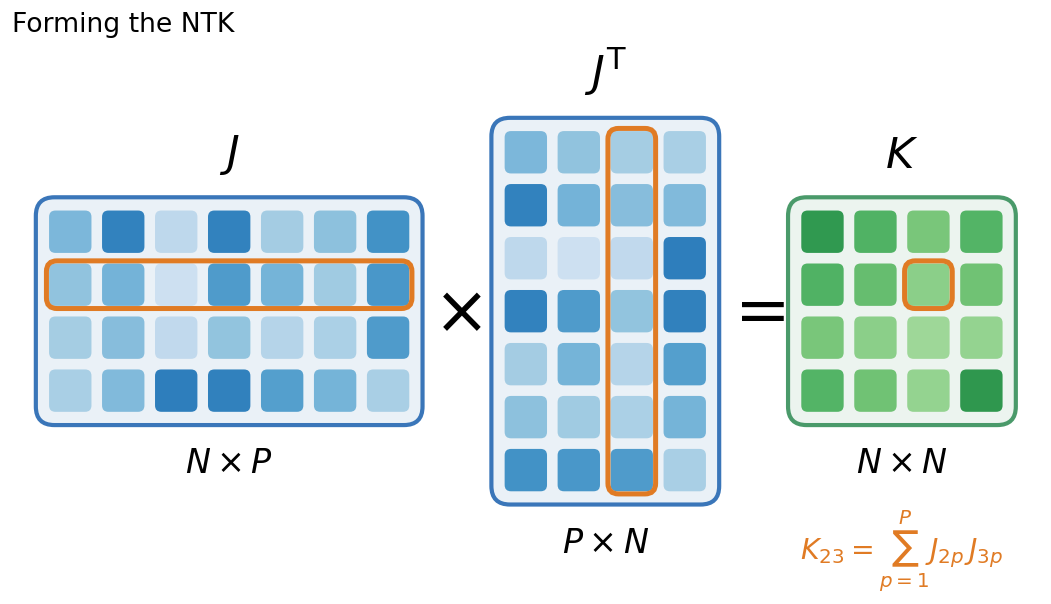

In [2]:
# draw_product and draw_kernel come from the plotting-helper cell before this one.
rng = np.random.default_rng(1)
draw_product(rng.uniform(0, 1, size=(4, 7)), title="Forming the NTK")
plt.show()

## 2. Now construct the NTK for a PINN

Suppose we have:

- $N_b$ boundary-condition points.
- $N_r$ PDE collocation points.

At boundary points, we evaluate $u_\theta(x_b)$.
At PDE points, we evaluate the residual

$$
r_\theta(x)=\mathcal D[u_\theta](x)-f(x)
$$

We construct two Jacobians:

$$
J_b=\frac{\partial \mathbf e_b}{\partial\theta},
\qquad
J_r=\frac{\partial \mathbf e_r}{\partial\theta}
$$

Then stack them:

$$
J_{\mathrm{PINN}}=
\begin{bmatrix}
J_b\\
J_r
\end{bmatrix}
$$

The PINN NTK becomes

$$
\boxed{
K_{\mathrm{PINN}}=
\begin{bmatrix}
J_bJ_b^T&J_bJ_r^T\\
J_rJ_b^T&J_rJ_r^T
\end{bmatrix}
}
$$

This is a matrix of size $(N_b+N_r)\times(N_b+N_r)$.
Its four blocks are $K_{bb}=J_bJ_b^T$, $K_{br}=J_bJ_r^T$, $K_{rb}=J_rJ_b^T$, and $K_{rr}=J_rJ_r^T$.

## 3. Numerical example

Consider the differential equation

$$
u''(x)=2,\qquad u(0)=u(1)=0
$$

whose exact solution is $u = x^2 - x$.
For simplicity, replace the neural network with a three-parameter function:

$$
u_\theta(x)=ax^2+bx+c
$$

So our parameters are $\theta=[a,b,c]^T$.
Take two boundary points, $x=0,1$, and one PDE point, $x=0.5$.
Our three errors are

$$
e_1=u(0)=c
$$

$$
e_2=u(1)=a+b+c
$$

$$
e_3=u''(0.5)-2=2a-2
$$

Differentiate each error with respect to $a,b,c$:

$$
J=
\begin{bmatrix}
0&0&1\\
1&1&1\\
2&0&0
\end{bmatrix}
$$

Now multiply:

$$
K=JJ^T
$$

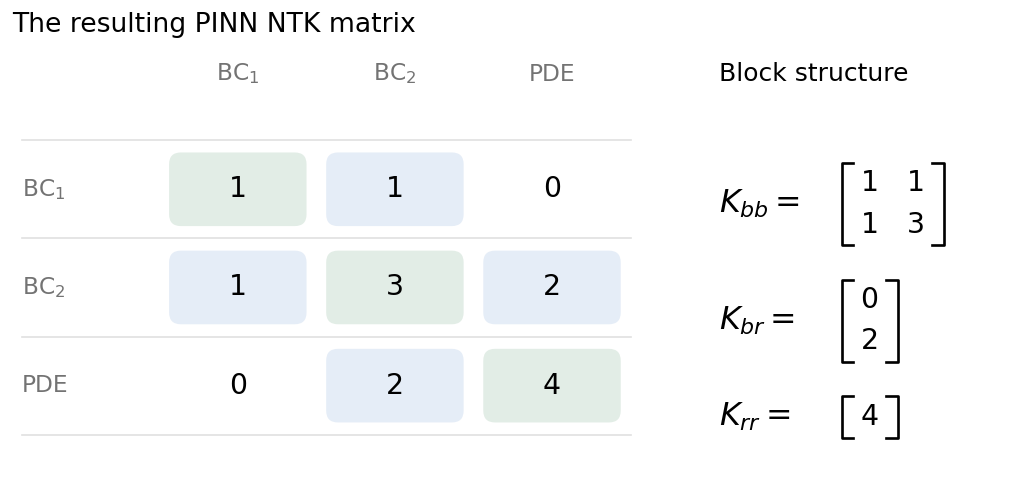

In [3]:
def quad_errors(theta):
    a, b, c = theta
    return np.array([c, a + b + c, 2 * a - 2])

# Rows of J are the gradients of e_1 = c, e_2 = a + b + c, and e_3 = 2a - 2 with respect to (a, b, c).
J_quad = np.array([[0.0, 0.0, 1.0],
                   [1.0, 1.0, 1.0],
                   [2.0, 0.0, 0.0]])
K_quad = J_quad @ J_quad.T
assert np.allclose(K_quad, [[1, 1, 0], [1, 3, 2], [0, 2, 4]])
draw_kernel(K_quad, ["BC$_1$", "BC$_2$", "PDE"], nb=2, title="The resulting PINN NTK matrix")
plt.show()

Notice something interesting.

- The first boundary condition and PDE residual have a kernel entry of zero. Correcting the PDE residual through this parameterization has no first-order effect on the first boundary value.
- The second boundary condition and PDE residual have a kernel entry of 2. They are coupled through parameter $a$.
- The diagonal entries measure the squared parameter sensitivities of each constraint.

This example has a constant NTK because our model is linear in its parameters. For a nonlinear neural network, these Jacobians generally change with training.

## 4. How do we use the matrix to understand training?

Suppose the loss is

$$
L=\frac12\|e_b\|^2+\frac12\|e_r\|^2
$$

Under continuous-time gradient descent,

$$
\dot\theta=-J^Te
$$

and therefore

$$
\boxed{\dot e=-JJ^Te=-Ke}
$$

This is where the NTK becomes useful.
Rather than examining the evolution of thousands of individual network weights, we can investigate the evolution of the errors through the much smaller kernel matrix.
For a fixed kernel, its eigenvalues tell us how rapidly different error patterns decay.

One gradient step in the numerical example shows the two kernel entries at work.
At $a=b=c=0$ both boundary errors are zero and $e_3=-2$, so $e=(0,0,-2)$.
The gradient is $J^Te=(-4,0,0)$, and a step of size $\eta$ raises $a$ by $4\eta$.
The errors change by $J\,\Delta\theta=(0,4\eta,8\eta)=-\eta Ke$.
The PDE residual moves toward zero by $8\eta$, and $e_2$, which was zero, grows to $4\eta$ because $K_{23}=2$.
The boundary value $u_\theta(0)=c$ stays at zero because $K_{13}=0$.
The model is linear in $\theta$, so this change is exact.

In [4]:
eta = 0.1
theta = np.zeros(3)
e = quad_errors(theta)
theta_next = theta - eta * J_quad.T @ e   # one gradient step on the loss e.e / 2
print("errors before the step  ", e)
print("change in the errors    ", quad_errors(theta_next) - e)
print("-eta K e                ", -eta * K_quad @ e)

errors before the step   [ 0.  0. -2.]
change in the errors     [0.  0.4 0.8]
-eta K e                 [0.  0.4 0.8]


One subtlety: if we have different weights $w_b,w_r$ for boundary and PDE losses, the equation becomes

$$
\dot e=-KW e,
\qquad
W=\begin{bmatrix}
w_bI&0\\0&w_rI
\end{bmatrix}.
$$

So the relevant training dynamics depend on both the NTK and the loss weights.

The key point is that we form the NTK matrix from parameter derivatives of the quantities we're trying to fit. In a PINN, those quantities include the PDE residual and boundary conditions, not merely the raw network output.

That is also why changing the PDE operator, collocation points, network architecture, or residual formulation changes the PINN's kernel and its learning dynamics.

## 5. Equal weights and the boundary loss

A PINN for the Poisson problem

$$
u''(x) = -\pi^2\sin(\pi x), \quad 0<x<1, \qquad u(0)=u(1)=0,
$$

has the exact solution $u=\sin(\pi x)$.
The boundary errors are $e_b = \big(u_\theta(0), u_\theta(1)\big)$, and the PDE residuals at the collocation points $x_j$ are $e_{r,j} = u_\theta''(x_j) + \pi^2\sin(\pi x_j)$.
The loss weights the two kinds of error,

$$
L(\theta) = \frac{w_b}{2}\|e_b\|^2 + \frac{w_r}{2}\|e_r\|^2 .
$$

Equal weights $w_b = w_r = 1$ give the two terms equal coefficients in the loss.
Do they also make the two errors decrease at the same rate?

While $K$ stays constant, the scaled errors $W^{1/2}e$ decay along the eigenvectors of $W^{1/2}KW^{1/2}$, each at a rate equal to its eigenvalue.
Equal weights give equal rates only when the boundary block $K_{bb}$ and the PDE block $K_{rr}$ have eigenvalues of similar size.
The numerical example meets this condition, with eigenvalues $2\mp\sqrt2 \approx 0.586$ and $3.414$ for $K_{bb}$ and $K_{rr} = 4$.

## 6. The NTK weights

Wang, Yu and Perdikaris (2022) choose the weights from the traces of the kernel blocks,

$$
w_b = \frac{\operatorname{tr}K}{\operatorname{tr}K_{bb}}, \qquad
w_r = \frac{\operatorname{tr}K}{\operatorname{tr}K_{rr}}, \qquad
\operatorname{tr}K = \operatorname{tr}K_{bb} + \operatorname{tr}K_{rr}.
$$

With these weights $w_b\operatorname{tr}K_{bb} = w_r\operatorname{tr}K_{rr} = \operatorname{tr}K$, so the two diagonal blocks of $W^{1/2}KW^{1/2}$ have the same trace.
When the cross blocks are zero, the trace of a block is the sum of the decay rates of its errors, and the boundary errors and the PDE residuals get the same total rate.
Each diagonal entry $K_{ii} = \|\nabla_\theta e_i\|^2$ is a squared gradient norm, so the weights need one gradient per training point and never the full kernel.

In the numerical example $\operatorname{tr}K_{bb} = 1 + 3 = 4$ and $\operatorname{tr}K_{rr} = 4$, so the NTK weights are $w_b = w_r = 8/4 = 2$.
Doubling both weights doubles every rate, which is the same as doubling the step size, so on this example the NTK weights change only the step.

In [5]:
def ntk_weights(K, nb):
    """NTK weights w_b = tr K / tr K_bb and w_r = tr K / tr K_rr. The first nb rows of K are boundary errors."""
    tr_bb, tr_rr = np.trace(K[:nb, :nb]), np.trace(K[nb:, nb:])
    return (tr_bb + tr_rr) / tr_bb, (tr_bb + tr_rr) / tr_rr

def weight_vector(n, nb, w_b, w_r):
    """Diagonal of W for nb boundary errors followed by n - nb PDE residuals."""
    return np.r_[np.full(nb, w_b), np.full(n - nb, w_r)]

def rates(K, w):
    """Eigenvalues of W^(1/2) K W^(1/2), the decay rates of the scaled errors."""
    sq = np.sqrt(w)
    return np.linalg.eigvalsh(sq[:, None] * K * sq[None, :])

w_b, w_r = ntk_weights(K_quad, 2)
print(f"NTK weights for the numerical example: w_b = {w_b:.3f}   w_r = {w_r:.3f}")

NTK weights for the numerical example: w_b = 2.000   w_r = 2.000


## 7. A sine model

The Poisson problem of Section 5 has the solution $\sin(\pi x)$, which no quadratic can represent.
The model $u_\theta(x) = a + bx + c\sin(\pi x)$ is linear in $\theta = (a,b,c)$, so its kernel also stays constant for the whole of training.
Like the numerical example, it trains on the two boundary points $x = 0, 1$ and on the PDE residual at $x = 0.5$.
The errors are $e_1 = u_\theta(0) = a$, $e_2 = u_\theta(1) = a+b$, and $e_3 = u_\theta''(0.5) + \pi^2 = \pi^2(1-c)$, with gradients $(1,0,0)$, $(1,1,0)$, and $(0,0,-\pi^2)$.
The second derivative of $\sin(\pi x)$ is $-\pi^2\sin(\pi x)$, so the PDE gradient has length $\pi^2$ and $K_{33} = \pi^4 \approx 97.409$, where the numerical example had $K_{33} = 4$.
The kernel is

$$
K = \begin{bmatrix}1&1&0\\1&2&0\\0&0&\pi^4\end{bmatrix}.
$$

The boundary block has eigenvalues $(3\mp\sqrt5)/2 \approx 0.382$ and $2.618$.
The cross blocks are zero because the line $a + bx$ has zero second derivative and $\sin(\pi x)$ vanishes at both ends.
The PDE residual sets $c$ alone, and only the boundary errors can set $a$ and $b$.

In [6]:
# Rows of J are the gradients of e_1 = a, e_2 = a + b, and e_3 = pi^2 (1 - c).
J_sine = np.array([[1.0, 0.0, 0.0],
                  [1.0, 1.0, 0.0],
                  [0.0, 0.0, -np.pi**2]])
K_sine = J_sine @ J_sine.T

sine_weights = {"equal weights": (1.0, 1.0), "NTK weights": ntk_weights(K_sine, 2)}
print(f"{'':14s} {'w_b':>7s} {'w_r':>7s}   boundary rates   PDE rate")
for name, (w_b, w_r) in sine_weights.items():
    # The blocks are uncoupled, so each block's rates are its weight times its eigenvalues.
    rb = w_b * np.linalg.eigvalsh(K_sine[:2, :2])
    rr = w_r * K_sine[2, 2]
    print(f"{name:14s} {w_b:7.3f} {w_r:7.4f}   {rb[0]:6.3f} {rb[1]:7.3f}   {rr:8.3f}")

                   w_b     w_r   boundary rates   PDE rate
equal weights    1.000  1.0000    0.382   2.618     97.409
NTK weights     33.470  1.0308   12.784  87.625    100.409


The NTK weights are $w_b = 100.409/3 = 33.470$ and $w_r = 100.409/97.409 = 1.031$.
They raise the two boundary rates by a factor of 33.47, to 12.784 and 87.625, and they raise the PDE rate from 97.409 to 100.409.

Gradient descent takes the steps $\theta \leftarrow \theta - \eta J^T We$.
A larger weight raises the largest eigenvalue $\lambda_{\max}$ of $W^{1/2}KW^{1/2}$, and the step must stay below $2/\lambda_{\max}$ for gradient descent to be stable.
Each run therefore uses $\eta = 1/(2\lambda_{\max})$ for its own weights, so the two runs take steps of the same size relative to their stability limits.
Both runs start from $(a,b,c) = (0.8,-0.3,0)$ and take 2,000 steps.
The animation below the printed table steps through both runs.
Its top row draws the solution and, dotted, its line part $a + bx$.
Adding a line to $u_\theta$ leaves every PDE residual unchanged, so only the boundary loss can remove $a + bx$.
Its bottom row marks the current step on the two unweighted loss terms $\tfrac12\|e_b\|^2$ and $\tfrac12\|e_r\|^2$.

In [7]:
def sine_errors(theta):
    a, b, c = theta
    return np.array([a, a + b, np.pi**2 * (1 - c)])

def train_sine(w_b, w_r, steps=2000, theta0=(0.8, -0.3, 0.0)):
    w = weight_vector(3, 2, w_b, w_r)
    eta = 0.5 / rates(K_sine, w).max()
    theta, history = np.array(theta0), []
    for k in range(steps + 1):
        e = sine_errors(theta)
        history.append((theta.copy(), 0.5 * e[:2] @ e[:2], 0.5 * e[2]**2))
        theta = theta - eta * J_sine.T @ (w * e)   # gradient step on the weighted loss
    return history

sine_runs = {name: train_sine(*w) for name, w in sine_weights.items()}

x = np.linspace(0, 1, 201)

for name, history in sine_runs.items():
    print(name)
    for k in (10, 20, 100, 1000, 2000):
        theta, L_b, L_r = history[k]
        print(f"  step {k:4d}   boundary loss {L_b:.1e}   PDE loss {L_r:.1e}   "
              f"(a, b, c) = ({theta[0]:+.3f}, {theta[1]:+.3f}, {theta[2]:.3f})")

equal weights
  step   10   boundary loss 3.6e-01   PDE loss 4.6e-05   (a, b, c) = (+0.737, -0.324, 0.999)
  step   20   boundary loss 2.9e-01   PDE loss 4.4e-11   (a, b, c) = (+0.681, -0.343, 1.000)
  step  100   boundary loss 8.3e-02   PDE loss 0.0e+00   (a, b, c) = (+0.407, -0.401, 1.000)
  step 1000   boundary loss 1.7e-03   PDE loss 0.0e+00   (a, b, c) = (+0.050, -0.081, 1.000)
  step 2000   boundary loss 3.4e-05   PDE loss 0.0e+00   (a, b, c) = (+0.007, -0.011, 1.000)
NTK weights
  step   10   boundary loss 2.3e-02   PDE loss 4.6e-05   (a, b, c) = (+0.185, -0.297, 0.999)
  step   20   boundary loss 6.3e-03   PDE loss 4.4e-11   (a, b, c) = (+0.095, -0.154, 1.000)
  step  100   boundary loss 1.7e-07   PDE loss 0.0e+00   (a, b, c) = (+0.000, -0.001, 1.000)
  step 1000   boundary loss 6.4e-59   PDE loss 0.0e+00   (a, b, c) = (+0.000, -0.000, 1.000)
  step 2000   boundary loss 4.7e-116   PDE loss 0.0e+00   (a, b, c) = (+0.000, -0.000, 1.000)


In [8]:
import base64, os, tempfile
from matplotlib.animation import FuncAnimation, FFMpegWriter, writers
from IPython.display import HTML, display

steps = np.arange(1, 2001)
frame_steps = np.unique(np.r_[0, np.round(np.logspace(0, np.log10(2000), 60)).astype(int)])
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), dpi=80)
panels = []
for col, ((name, history), color) in enumerate(zip(sine_runs.items(), ["tab:blue", "tab:green"])):
    ax = axes[0, col]
    ax.plot(x, np.sin(np.pi * x), "--", color="#333333", lw=2, zorder=5, label="exact")
    line, = ax.plot([], [], color=color, lw=2.5, label=name)
    tilt, = ax.plot([], [], ":", color="0.4", lw=2, label="a + bx")
    ax.scatter([0, 1], [0, 0], color="tab:red", s=80, zorder=6)
    ax.set(xlim=(0, 1), ylim=(-0.4, 1.9), xlabel="x", ylabel="u(x)", title=name)
    ax.legend(loc="upper right")
    text = ax.text(0.03, 0.05, "", transform=ax.transAxes)
    ax = axes[1, col]
    ax.loglog(steps, [history[k][1] for k in steps], color="tab:blue", lw=2.5, label="boundary loss")
    ax.loglog(steps, [max(history[k][2], 1e-300) for k in steps], "--", color="tab:orange", lw=2, label="PDE loss")
    cursor = ax.axvline(1, color="0.4", ls=":")
    ax.set(xlabel="gradient-descent step", ylabel="loss term", ylim=(1e-12, 1e2))
    ax.legend(loc="lower left")
    panels.append((line, tilt, text, cursor, history))
title = fig.suptitle("")
fig.tight_layout(rect=[0, 0, 1, 0.95])

def draw_frame(i):
    k = frame_steps[i]
    for line, tilt, text, cursor, history in panels:
        (a, b, c), L_b, L_r = history[k]
        line.set_data(x, a + b * x + c * np.sin(np.pi * x))
        tilt.set_data(x, a + b * x)
        text.set_text(f"boundary loss {L_b:.1e}\nPDE loss {L_r:.1e}")
        cursor.set_xdata([max(k, 1), max(k, 1)])
    title.set_text(f"Sine model, step {k:,}")

animation = FuncAnimation(fig, draw_frame, frames=len(frame_steps))
if writers.is_available("ffmpeg"):
    # Jupyter removes scripts from a notebook it has not trusted, and a <video> tag needs none.
    mp4 = os.path.join(tempfile.mkdtemp(), "training.mp4")
    animation.save(mp4, writer=FFMpegWriter(fps=6))
    with open(mp4, "rb") as f:
        video = base64.b64encode(f.read()).decode()
    html = f'<video controls loop width="100%" src="data:video/mp4;base64,{video}"></video>'
else:
    html = animation.to_jshtml(fps=6, default_mode="once")
plt.close(fig)
display(HTML(html))
print(f"{len(frame_steps)} frames from step 0 to step {frame_steps[-1]:,}")

52 frames from step 0 to step 2,000


The PDE mode has the largest rate in both runs, so $\eta\lambda_{\max} = 1/2$ halves the PDE residual at every step.
The coefficient $c$ reaches 1 within 20 steps, and the PDE loss is $4\times10^{-11}$ at step 20 with either weighting.
With equal weights the slowest boundary mode shrinks by the factor $1 - 0.382/(2\times 97.409) = 0.998$ per step, which takes 510 steps to reduce its error by a factor of $e$.
At step 100 the solution is $\sin(\pi x) + 0.407 - 0.401x$, the correct curvature on a tilted line, and the boundary loss is $8.3\times10^{-2}$.
With the NTK weights the factor is $1 - 12.784/(2\times 100.409) = 0.936$, which takes 15 steps per factor of $e$, and the boundary loss at step 100 is $1.7\times10^{-7}$.
With equal weights the boundary loss is still .4	imes10^{-5}$ at step 2,000, and the dotted line has not reached zero.


## 8. Limits of the NTK weights

The NTK weights equalize the traces of the two blocks, and the slow modes inside the PDE block stay slow.
Those modes carry the high-frequency part of the residual, so the weights do not remove spectral bias.
The rate analysis assumes gradient descent and a kernel that changes little during training.
The sine model has a constant kernel and zero cross blocks.
A neural network has a kernel that changes during training and nonzero cross blocks, so Wang, Yu and Perdikaris recompute the weights from the current kernel as training proceeds.
Adam rescales the step of each parameter, so under Adam the errors no longer follow $\dot e = -KWe$, and the same weights become a heuristic.
For a nonlinear PDE the residual Jacobian contains the linearization of the operator at the current solution, so $K_{rr}$ changes with $u_\theta$ even when the network is very wide.

## Sources

1. S. Wang, X. Yu and P. Perdikaris, When and why PINNs fail to train: a neural tangent kernel perspective, Journal of Computational Physics 449 (2022) 110768. [arXiv:2007.14527](https://arxiv.org/abs/2007.14527)
2. A. Jacot, F. Gabriel and C. Hongler, Neural tangent kernel: convergence and generalization in neural networks, NeurIPS 2018. [arXiv:1806.07572](https://arxiv.org/abs/1806.07572)